# 04 — Standardization and Scaling Demo

## Task 3: regression — synthetic crop-yield dataset

This notebook demonstrates numerical scaling for a regression problem after preprocessing, EDA, and feature engineering.

It is intentionally a **simple demo**. It does not construct a pipeline and it does not train a predictive model. Predictor scaling and optional target scaling are shown as separate operations so their roles remain explicit.

## Learning objectives

After completing this notebook, students should be able to:

- split a regression dataset before fitting scaling parameters;
- scale numerical predictors without changing binary categorical indicators;
- compare StandardScaler, MinMaxScaler, RobustScaler, and MaxAbsScaler;
- distinguish predictor scaling from target scaling;
- standardize a continuous target when appropriate;
- return a standardized target to its original scientific units with `inverse_transform()`;
- understand why target scaling is optional rather than universally required;
- distinguish linear scaling from distribution-shaping transformations.

## 1. Scope and leakage rule

The same rule applies in regression:

```text
engineered dataset
      ↓
train / test split
      ↓
fit transformations using TRAIN only
      ↓
transform TRAIN and TEST with the same fitted objects
```

For regression there may be **two** independent scalers:

```text
X scaler -> numerical predictors
y scaler -> optional continuous target transformation
```

These objects learn different quantities and should not be confused.

## 2. Imports and reproducibility

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import (
    StandardScaler,
    MinMaxScaler,
    RobustScaler,
    MaxAbsScaler,
    PowerTransformer,
    QuantileTransformer,
)

from IPython.display import display

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid", context="notebook")

## 3. Project paths

In [2]:
def find_project_root(start: Path) -> Path:
    start = start.resolve()
    for candidate in [start, *start.parents]:
        if (candidate / "data").is_dir() and (candidate / "notebooks").is_dir():
            return candidate
    raise FileNotFoundError(
        "Could not locate the repository root. Run the notebook from inside the project."
    )

PROJECT_ROOT = find_project_root(Path.cwd())

FEATURE_DATA_PATH = (
    PROJECT_ROOT / "data" / "synthetic_crop_yield" / "feature_data" / "synthetic_crop_yield_engineered.csv"
)
PREPROCESSING_REPORT_PATH = (
    PROJECT_ROOT / "data" / "synthetic_crop_yield" / "processed_data" / "preprocessing_report.json"
)

print("Project root:", PROJECT_ROOT)
print("Feature data:", FEATURE_DATA_PATH.relative_to(PROJECT_ROOT))

Project root: /home/david/Desktop/depto_computacion/ml_2026/demos_machine_learning_2026
Feature data: data/synthetic_crop_yield/feature_data/synthetic_crop_yield_engineered.csv


## 4. Load the engineered dataset

This notebook expects `03_feature_engineering_and_selection.ipynb` to have been run first.

In [3]:
if not FEATURE_DATA_PATH.exists():
    raise FileNotFoundError(
        "Engineered feature data are missing. Run 03_feature_engineering_and_selection.ipynb first."
    )
if not PREPROCESSING_REPORT_PATH.exists():
    raise FileNotFoundError(
        "Preprocessing report is missing. Run 01_tabular_data_preprocessing.ipynb first."
    )

df = pd.read_csv(FEATURE_DATA_PATH)
with PREPROCESSING_REPORT_PATH.open("r", encoding="utf-8") as file:
    preprocessing_report = json.load(file)

ID_COLUMN = "plot_id"
TARGET_COLUMN = "yield_t_ha"
CATEGORICAL_COLUMNS = [
    "irrigation_system_drip",
    "cultivar_improved",
    "previous_legume_crop",
    "organic_management",
    "fungicide_used",
    "drought_event",
]
NUMERICAL_COLUMNS = [
    column for column in df.columns
    if column not in [ID_COLUMN, TARGET_COLUMN, *CATEGORICAL_COLUMNS]
    and pd.api.types.is_numeric_dtype(df[column])
]

print("Shape:", df.shape)
print("Numerical predictors:", len(NUMERICAL_COLUMNS))
print("Categorical indicators:", len(CATEGORICAL_COLUMNS))
print("Continuous target:", TARGET_COLUMN)
display(df.head())

Shape: (1200, 30)
Numerical predictors: 22
Categorical indicators: 6
Continuous target: yield_t_ha


,plot_id,mean_temperature_c,season_rainfall_mm,soil_ph,soil_organic_matter_pct,nitrogen_kg_ha,phosphorus_kg_ha,potassium_kg_ha,irrigation_mm,solar_radiation_mj_m2_day,...,yield_t_ha,total_water_mm,npk_total_kg_ha,n_to_p_ratio,mean_temperature_c_squared,soil_ph_squared,soil_moisture_pct_squared,water_x_drought,pest_x_fungicide,organic_matter_x_moisture
0,CP0001,20.7,273.7,7.21,3.80,136.6,57.4,38.5,88.3,15.4,...,5.38,362.0,232.5,2.379791,428.49,51.9841,795.24,0.0,2.7,107.160
1,CP0002,24.6,237.9,7.10,2.76,155.4,56.3,113.9,270.5,15.4,...,3.93,508.4,325.6,2.760213,605.16,50.4100,767.29,508.4,6.3,76.452
2,CP0003,20.4,192.5,7.16,2.95,121.6,51.9,49.6,62.2,14.6,...,3.10,254.7,223.1,2.342967,416.16,51.2656,449.44,254.7,0.0,62.540
3,CP0004,24.6,599.3,6.60,4.79,182.7,81.5,97.3,137.4,19.7,...,6.61,736.7,361.5,2.241718,605.16,43.5600,1108.89,0.0,0.0,159.507
4,CP0005,11.0,603.6,6.62,2.97,122.8,47.8,97.2,76.1,15.8,...,0.70,679.7,267.8,2.569038,121.00,43.8244,1225.00,0.0,7.2,103.950


## 5. Split before fitting any scaler

For this simple regression demo we use a reproducible random split. The test set remains untouched while transformation parameters are learned.

In [4]:
train_df, test_df = train_test_split(
    df,
    test_size=0.20,
    random_state=RANDOM_STATE,
)

X_train = train_df[NUMERICAL_COLUMNS + CATEGORICAL_COLUMNS].copy()
X_test = test_df[NUMERICAL_COLUMNS + CATEGORICAL_COLUMNS].copy()
y_train = train_df[TARGET_COLUMN].copy()
y_test = test_df[TARGET_COLUMN].copy()

display(pd.DataFrame({
    "partition": ["train", "test"],
    "n": [len(train_df), len(test_df)],
    "target_mean_t_ha": [y_train.mean(), y_test.mean()],
    "target_std_t_ha": [y_train.std(), y_test.std()],
}).round(3))

,partition,n,target_mean_t_ha,target_std_t_ha
0,train,960,4.268,1.485
1,test,240,4.334,1.410


## 6. Inspect the original numerical scales

In [5]:
raw_scale_summary = X_train[NUMERICAL_COLUMNS].agg(
    ["mean", "std", "min", "median", "max"]
).T
raw_scale_summary["range"] = raw_scale_summary["max"] - raw_scale_summary["min"]
raw_scale_summary = raw_scale_summary.sort_values("range", ascending=False)
display(raw_scale_summary.round(3))

,mean,std,min,median,max,range
soil_moisture_pct_squared,1004.388,408.140,213.160,954.810,2304.00,2090.840
water_x_drought,118.992,241.895,0.000,0.000,999.60,999.600
total_water_mm,542.746,179.353,153.000,522.850,1090.40,937.400
mean_temperature_c_squared,469.100,159.638,121.000,449.440,1049.76,928.760
season_rainfall_mm,392.391,158.259,90.000,373.900,850.00,760.000
irrigation_mm,150.356,84.710,13.500,132.550,420.00,406.500
npk_total_kg_ha,259.454,51.673,68.900,260.800,411.30,342.400
organic_matter_x_moisture,93.368,38.559,21.021,85.662,307.50,286.479
nitrogen_kg_ha,123.832,40.847,20.000,124.500,240.00,220.000
potassium_kg_ha,78.160,25.153,15.000,77.600,156.20,141.200


# Part I — Predictor scaling

## 7. StandardScaler for numerical predictors

The target remains in `t/ha` in this section. Only the numerical predictor matrix is standardized.

In [6]:
standard_scaler = StandardScaler()

X_train_standard = X_train.copy()
X_test_standard = X_test.copy()

X_train_standard[NUMERICAL_COLUMNS] = standard_scaler.fit_transform(
    X_train[NUMERICAL_COLUMNS]
)
X_test_standard[NUMERICAL_COLUMNS] = standard_scaler.transform(
    X_test[NUMERICAL_COLUMNS]
)

standard_check = pd.DataFrame({
    "train_mean": X_train_standard[NUMERICAL_COLUMNS].mean(),
    "train_std_ddof0": X_train_standard[NUMERICAL_COLUMNS].std(ddof=0),
    "test_mean": X_test_standard[NUMERICAL_COLUMNS].mean(),
    "test_std_ddof0": X_test_standard[NUMERICAL_COLUMNS].std(ddof=0),
})
display(standard_check.round(3))

,train_mean,train_std_ddof0,test_mean,test_std_ddof0
mean_temperature_c,-0.0,1.0,-0.080,1.013
season_rainfall_mm,0.0,1.0,-0.024,0.946
soil_ph,0.0,1.0,-0.020,0.980
soil_organic_matter_pct,0.0,1.0,-0.040,0.965
nitrogen_kg_ha,0.0,1.0,0.141,1.075
phosphorus_kg_ha,-0.0,1.0,0.061,1.014
potassium_kg_ha,-0.0,1.0,0.046,1.061
irrigation_mm,0.0,1.0,0.103,0.998
solar_radiation_mj_m2_day,-0.0,1.0,0.069,1.010
field_slope_pct,0.0,1.0,-0.063,0.981


## 8. Verify categorical indicators remain 0/1

In [7]:
for column in CATEGORICAL_COLUMNS:
    assert X_train_standard[column].equals(X_train[column])
    assert X_test_standard[column].equals(X_test[column])

print("PASS — categorical indicators remain unchanged.")
print("Target still uses original units (t/ha):", y_train.dtype)

PASS — categorical indicators remain unchanged.
Target still uses original units (t/ha): float64


## 9. Standardized predictors versus the continuous target

Scaling the x-axis does not create or destroy a relationship. A positive affine transformation preserves Pearson and rank correlations. Here the target is used only for visualization.

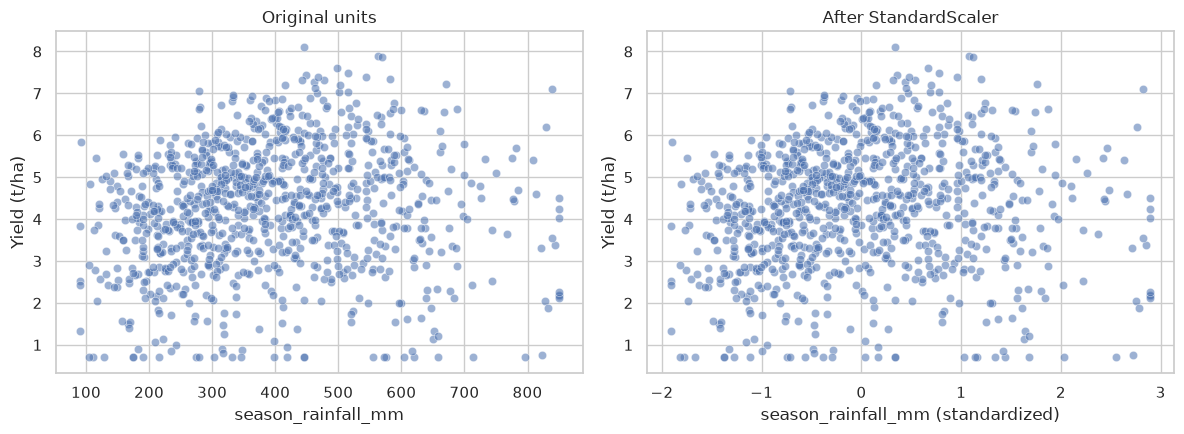

Pearson raw: 0.1089
Pearson standardized: 0.1089


In [8]:
REPRESENTATIVE_FEATURES = [
    "season_rainfall_mm",
    "soil_ph",
    "nitrogen_kg_ha",
    "mean_temperature_c_squared",
]

feature = "season_rainfall_mm"
plot_df = pd.DataFrame({
    "raw_feature": X_train[feature],
    "standardized_feature": X_train_standard[feature],
    "yield_t_ha": y_train,
})

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.scatterplot(data=plot_df, x="raw_feature", y="yield_t_ha", alpha=0.55, ax=axes[0])
axes[0].set_title("Original units")
axes[0].set_xlabel(feature)
axes[0].set_ylabel("Yield (t/ha)")

sns.scatterplot(data=plot_df, x="standardized_feature", y="yield_t_ha", alpha=0.55, ax=axes[1])
axes[1].set_title("After StandardScaler")
axes[1].set_xlabel(f"{feature} (standardized)")
axes[1].set_ylabel("Yield (t/ha)")

plt.tight_layout()
plt.show()

print("Pearson raw:", round(plot_df[["raw_feature", "yield_t_ha"]].corr().iloc[0, 1], 4))
print("Pearson standardized:", round(plot_df[["standardized_feature", "yield_t_ha"]].corr().iloc[0, 1], 4))

# Part II — Compare common feature-wise scalers

## 10. Alternative predictor scalers

In [9]:
scalers = {
    "StandardScaler": StandardScaler(),
    "MinMaxScaler": MinMaxScaler(),
    "RobustScaler": RobustScaler(),
    "MaxAbsScaler": MaxAbsScaler(),
}

scaled_train = {}
scaled_test = {}

for name, scaler in scalers.items():
    scaled_train[name] = pd.DataFrame(
        scaler.fit_transform(X_train[NUMERICAL_COLUMNS]),
        columns=NUMERICAL_COLUMNS,
        index=X_train.index,
    )
    scaled_test[name] = pd.DataFrame(
        scaler.transform(X_test[NUMERICAL_COLUMNS]),
        columns=NUMERICAL_COLUMNS,
        index=X_test.index,
    )

print(list(scalers))

['StandardScaler', 'MinMaxScaler', 'RobustScaler', 'MaxAbsScaler']


## 11. Numerical comparison for one predictor

In [10]:
def summarize_transformation(name, train_values, test_values):
    train_values = np.asarray(train_values, dtype=float).ravel()
    test_values = np.asarray(test_values, dtype=float).ravel()
    q1, q3 = np.quantile(train_values, [0.25, 0.75])
    return {
        "method": name,
        "train_mean": train_values.mean(),
        "train_std_ddof0": train_values.std(ddof=0),
        "train_median": np.median(train_values),
        "train_iqr": q3 - q1,
        "train_min": train_values.min(),
        "train_max": train_values.max(),
        "test_min": test_values.min(),
        "test_max": test_values.max(),
    }

comparison_feature = "season_rainfall_mm"
rows = [
    summarize_transformation(
        "Raw",
        X_train[comparison_feature],
        X_test[comparison_feature],
    )
]
for name in scalers:
    rows.append(
        summarize_transformation(
            name,
            scaled_train[name][comparison_feature],
            scaled_test[name][comparison_feature],
        )
    )

comparison_table = pd.DataFrame(rows).set_index("method")
display(comparison_table.round(3))

,train_mean,train_std_ddof0,train_median,train_iqr,train_min,train_max,test_min,test_max
method,,,,,,,,
Raw,392.391,158.176,373.900,223.025,90.000,850.000,90.000,850.000
StandardScaler,0.000,1.000,-0.117,1.410,-1.912,2.893,-1.912,2.893
MinMaxScaler,0.398,0.208,0.374,0.293,0.000,1.000,0.000,1.000
RobustScaler,0.083,0.709,0.000,1.000,-1.273,2.135,-1.273,2.135
MaxAbsScaler,0.462,0.186,0.440,0.262,0.106,1.000,0.106,1.000


## 12. Visual comparison of the same predictor

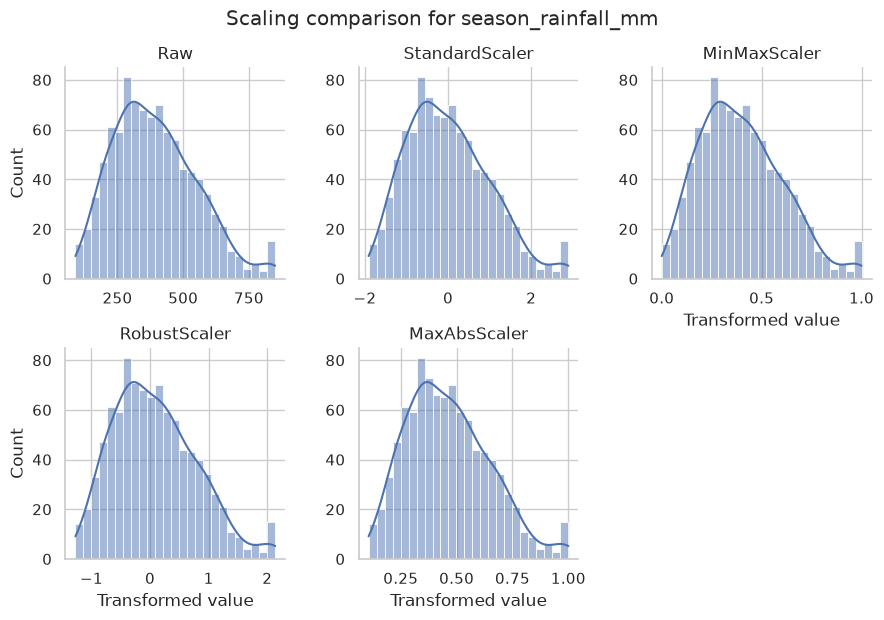

In [11]:
frames = [
    pd.DataFrame({"value": X_train[comparison_feature], "method": "Raw"})
]
for name in scalers:
    frames.append(pd.DataFrame({
        "value": scaled_train[name][comparison_feature],
        "method": name,
    }))
comparison_long = pd.concat(frames, ignore_index=True)

g = sns.FacetGrid(
    comparison_long,
    col="method",
    col_wrap=3,
    sharex=False,
    sharey=False,
    height=3.0,
)
g.map_dataframe(sns.histplot, x="value", kde=True, bins=25)
g.set_axis_labels("Transformed value", "Count")
g.set_titles("{col_name}")
g.figure.suptitle(f"Scaling comparison for {comparison_feature}", y=1.03)
plt.show()

# Part III — Optional target scaling

## 13. Standardize the continuous target separately

Unlike a classification label, a regression target is numerical and **can** be transformed. This is optional. The decision depends on the model and optimization problem.

We use a completely separate scaler for `y`.

In [12]:
y_scaler = StandardScaler()

y_train_scaled = y_scaler.fit_transform(
    y_train.to_numpy().reshape(-1, 1)
).ravel()
y_test_scaled = y_scaler.transform(
    y_test.to_numpy().reshape(-1, 1)
).ravel()

print("Training target mean after scaling:", round(y_train_scaled.mean(), 8))
print("Training target std after scaling:", round(y_train_scaled.std(ddof=0), 8))
print("Test target mean after training-based scaling:", round(y_test_scaled.mean(), 4))

Training target mean after scaling: 0.0
Training target std after scaling: 1.0
Test target mean after training-based scaling: 0.0442


## 14. Inverse transformation returns predictions to t/ha

A model trained against a standardized target would produce predictions in standardized units. Before scientific interpretation, predictions must be returned to the original target scale.

In [13]:
# Demonstration using five standardized target values.
example_scaled_predictions = y_test_scaled[:5]
example_original_units = y_scaler.inverse_transform(
    example_scaled_predictions.reshape(-1, 1)
).ravel()

inverse_demo = pd.DataFrame({
    "scaled_value": example_scaled_predictions,
    "back_to_t_ha": example_original_units,
    "original_y_test": y_test.iloc[:5].to_numpy(),
})
display(inverse_demo.round(4))

assert np.allclose(
    example_original_units,
    y_test.iloc[:5].to_numpy(),
)
print("PASS — inverse transformation restores the original target units.")

,scaled_value,back_to_t_ha,original_y_test
0,0.9307,5.65,5.65
1,-0.2617,3.88,3.88
2,0.0617,4.36,4.36
3,1.1463,5.97,5.97
4,-1.5349,1.99,1.99


PASS — inverse transformation restores the original target units.


### When would target scaling help?

Possible examples include neural networks, some gradient-based optimizers, or situations where the numerical magnitude of the target creates optimization difficulties.

It is usually unnecessary for tree-based regression and is not an obligatory step for ordinary regression analysis. Keeping the target in `t/ha` is often preferable for direct interpretation.

# Part IV — Distribution-shaping transformations

## 15. Scaling versus changing the distribution shape

In [14]:
shape_feature = "pest_pressure_score_0_10"

power = PowerTransformer(method="yeo-johnson", standardize=True)
quantile = QuantileTransformer(
    n_quantiles=min(200, len(X_train)),
    output_distribution="normal",
    random_state=RANDOM_STATE,
)

raw_train = X_train[[shape_feature]].to_numpy()
power_train = power.fit_transform(raw_train).ravel()
quantile_train = quantile.fit_transform(raw_train).ravel()

shape_summary = pd.DataFrame({
    "representation": ["Raw", "Yeo-Johnson + standardize", "Quantile -> normal"],
    "mean": [raw_train.mean(), power_train.mean(), quantile_train.mean()],
    "std": [raw_train.std(ddof=0), power_train.std(ddof=0), quantile_train.std(ddof=0)],
    "skewness": [
        pd.Series(raw_train.ravel()).skew(),
        pd.Series(power_train).skew(),
        pd.Series(quantile_train).skew(),
    ],
})
display(shape_summary.round(3))

,representation,mean,std,skewness
0,Raw,3.483,1.793,0.383
1,Yeo-Johnson + standardize,-0.000,1.000,-0.049
2,Quantile -> normal,0.002,1.016,0.020


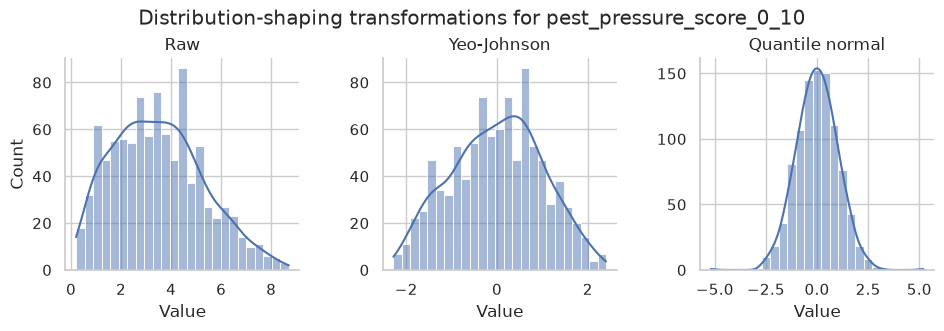

In [15]:
shape_long = pd.concat([
    pd.DataFrame({"value": raw_train.ravel(), "representation": "Raw"}),
    pd.DataFrame({"value": power_train, "representation": "Yeo-Johnson"}),
    pd.DataFrame({"value": quantile_train, "representation": "Quantile normal"}),
], ignore_index=True)

g = sns.FacetGrid(
    shape_long,
    col="representation",
    sharex=False,
    sharey=False,
    height=3.2,
)
g.map_dataframe(sns.histplot, x="value", kde=True, bins=25)
g.set_axis_labels("Value", "Count")
g.set_titles("{col_name}")
g.figure.suptitle(f"Distribution-shaping transformations for {shape_feature}", y=1.03)
plt.show()

# Part V — Deliberate stopping point

## 16. What this notebook does not do

This notebook does **not** save a final model-ready matrix and does not choose one universal scaler.

It also does not:

- fit a regression model;
- compare predictive performance;
- run cross-validation;
- combine feature selection and scaling in a pipeline;
- decide automatically whether the target should be transformed.

Those questions belong to the later full-preparation and modelling notebooks.

## 17. Take-home summary

For regression, remember the distinction:

```text
X numerical predictors -> may need feature-wise scaling
y continuous target    -> may optionally be transformed with a separate scaler
binary indicators      -> kept as 0/1 in this demo
identifier             -> excluded
```

Scaling predictors and scaling the target solve different problems. Every learned transformation must be fitted using training data only, and a transformed target must be returned to its original units before scientific interpretation.